# 01 · Test setup (paper Sec. IV and Sec. III-A)

What the paper specifies:
* Clean ECG from the MIT-BIH Arrhythmia Database; BW, EM and MA from the MIT-BIH Noise Stress Test Database; PLI is a 60 Hz sinusoid.
* The BW, EM and MA noises added to the ECG are **shifted and passed through different filters**, so they are correlated with, but not equal to, the reference noises given to the adaptive filters.
* EMD gives IMF1..IMF8 plus a residue r. Metrics are SNR, RMSE and SNRimp (Eqs. 4–6).

The paper doesn't specify these details. The choices used here:

| Detail | Choice |
|---|---|
| Signal length | whole record (650 000 samples, 30 min at 360 Hz), channel 0, no preprocessing |
| Noise amplitudes | NSTDB records at their recorded amplitudes; PLI with the same power as BW; total scaled to SNRin |
| Shift / filter | BW: 3-sample delay, FIR [0.6, 0.4]; EM: 5 samples, [0.4, 0.3, 0.2, 0.1]; MA: 4 samples, [0.5, 0.3, 0.2]. PLI is not shifted (the paper lists only BW, EM, MA) |
| EMD | MATLAB `emd` defaults (spline envelopes, relative tolerance 0.2, ≤ 100 sifts), 8 IMFs |
| Adaptive filter | LMS. The MATLAB default (step 0.1, 32 taps) diverges on these signals, so step size and taps come from the sweep in notebook 02, which only runs settings below the LMS stability limit |


In [8]:
from pathlib import Path
import sys, json

project_root = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

RESULTS = project_root / "results"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
METHOD_COLORS = {"PEAF": "#1f3b73", "SEAF": "#9aa83a", "PDAF": "#d62728", "SDAF": "#3cb9a0"}


In [9]:
from src.data_load import make_noisy_ecg, NOISE_PATHS
from src.EMD import emd_decompose
from src.adaptive_filters import snr_db, rmse, snr_improvement
from scipy.signal import welch

case = make_noisy_ecg(100, ("bw", "em", "ma"), pli=True, snr_db=10)
fs = case["fs"]
print(f"record 100: {len(case['clean'])} samples, fs = {fs} Hz")
print(f"measured SNRin = {snr_db(case['clean'], case['noisy']):.3f} dB (target 10 dB)")
pd.DataFrame({k: {"power (mV^2)": np.mean(v**2), "RMS (mV)": np.sqrt(np.mean(v**2))}
              for k, v in case["components"].items()}).T.round(5)

record 100: 65000 samples, fs = 360 Hz
measured SNRin = 10.000 dB (target 10 dB)


,power (mV^2),RMS (mV)
bw,0.00340,0.05828
em,0.00640,0.07999
ma,0.00054,0.02314
pli,0.00340,0.05828


## Clean, noisy and each noise component (first 10 s)

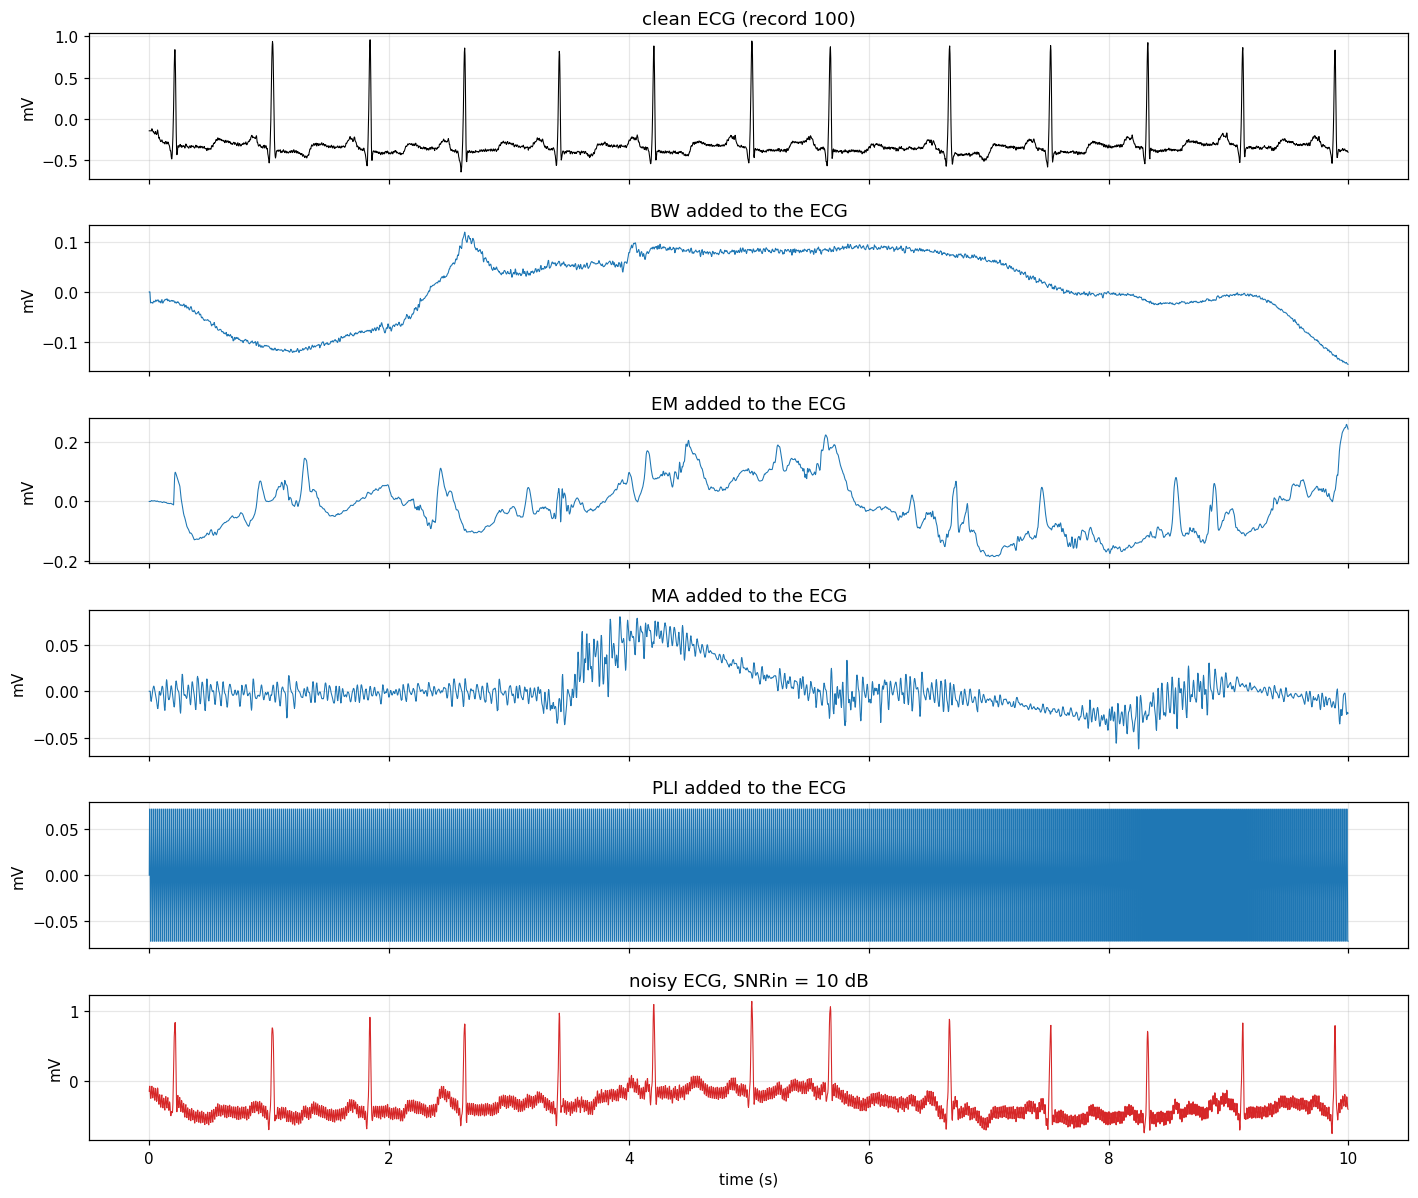

In [10]:
t = np.arange(10 * fs) / fs
fig, axes = plt.subplots(6, 1, figsize=(13, 11), sharex=True)
axes[0].plot(t, case["clean"][: len(t)], lw=0.7, color="k"); axes[0].set_title("clean ECG (record 100)")
for ax, (name, comp) in zip(axes[1:5], case["components"].items()):
    ax.plot(t, comp[: len(t)], lw=0.7); ax.set_title(f"{name.upper()} added to the ECG")
axes[5].plot(t, case["noisy"][: len(t)], lw=0.7, color="tab:red"); axes[5].set_title("noisy ECG, SNRin = 10 dB")
axes[5].set_xlabel("time (s)")
for ax in axes: ax.set_ylabel("mV")
plt.tight_layout(); plt.show()

## Reference noise vs noise added to the ECG

The noise added to the ECG is the reference, delayed and low-pass filtered: correlated, but not equal.

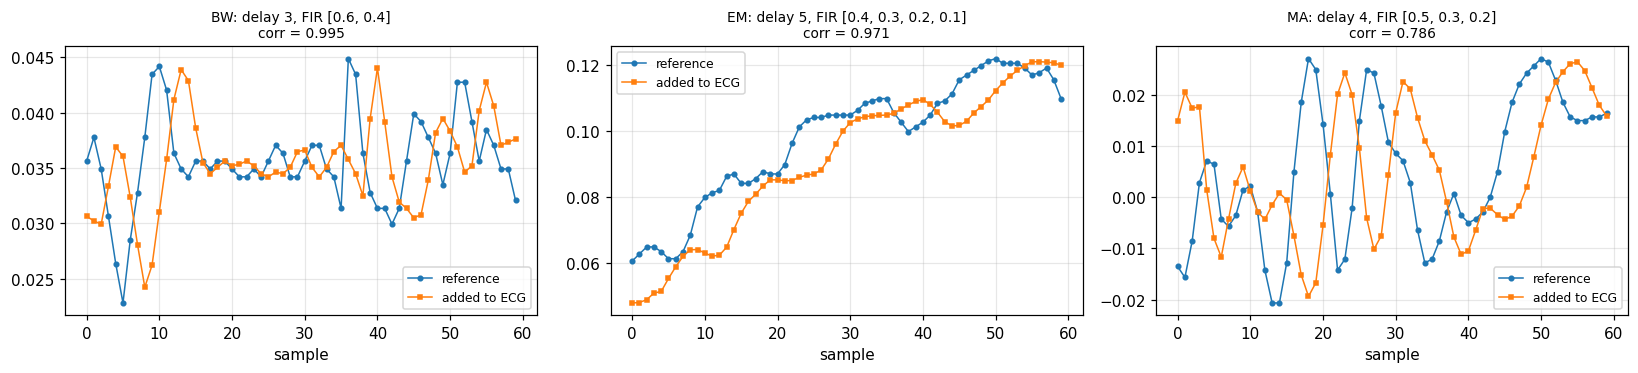

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, name in zip(axes, ["bw", "em", "ma"]):
    i0 = 100 * fs; w = slice(i0, i0 + 60)
    ax.plot(np.arange(60), case["references"][name][w], "o-", ms=3, lw=1, label="reference")
    ax.plot(np.arange(60), case["components"][name][w], "s-", ms=3, lw=1, label="added to ECG")
    d, h = NOISE_PATHS[name]
    corr = np.corrcoef(case["references"][name], case["components"][name])[0, 1]
    ax.set_title(f"{name.upper()}: delay {d}, FIR {h}\ncorr = {corr:.3f}", fontsize=9)
    ax.set_xlabel("sample"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Noise spectra

Sec. III-A: PLI is a single frequency, BW is concentrated in 0–3 Hz, EM is high frequency, MA overlaps the ECG.

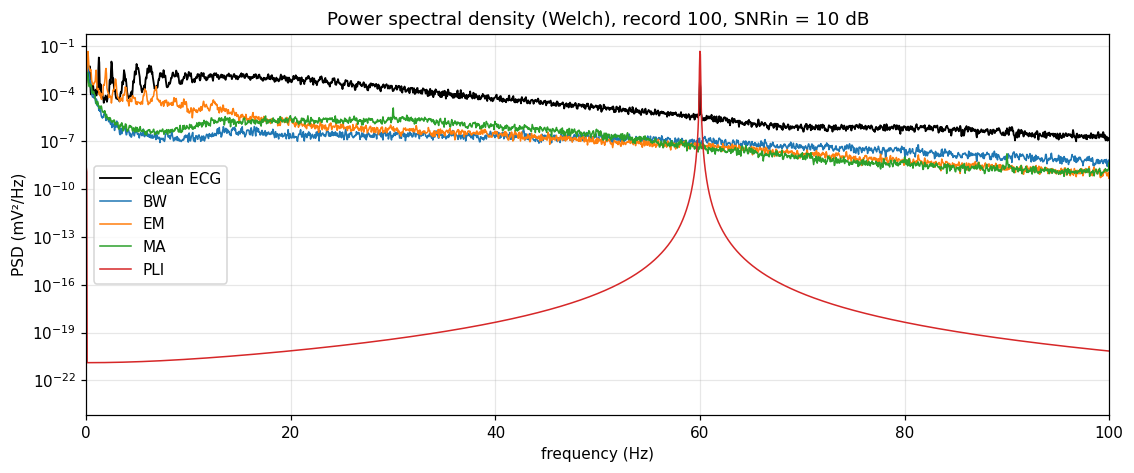

In [12]:
fig, ax = plt.subplots(figsize=(12, 4.5))
f, P = welch(case["clean"] - case["clean"].mean(), fs, nperseg=8192)
ax.semilogy(f, P, color="k", lw=1.2, label="clean ECG")
for name, comp in case["components"].items():
    f, P = welch(comp, fs, nperseg=8192)
    ax.semilogy(f, P, lw=1, label=name.upper())
ax.set_xlim(0, 100); ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("PSD (mV²/Hz)")
ax.legend(); ax.set_title("Power spectral density (Welch), record 100, SNRin = 10 dB")
plt.show()

## EMD of the noisy ECG: IMF1..IMF8 and residue

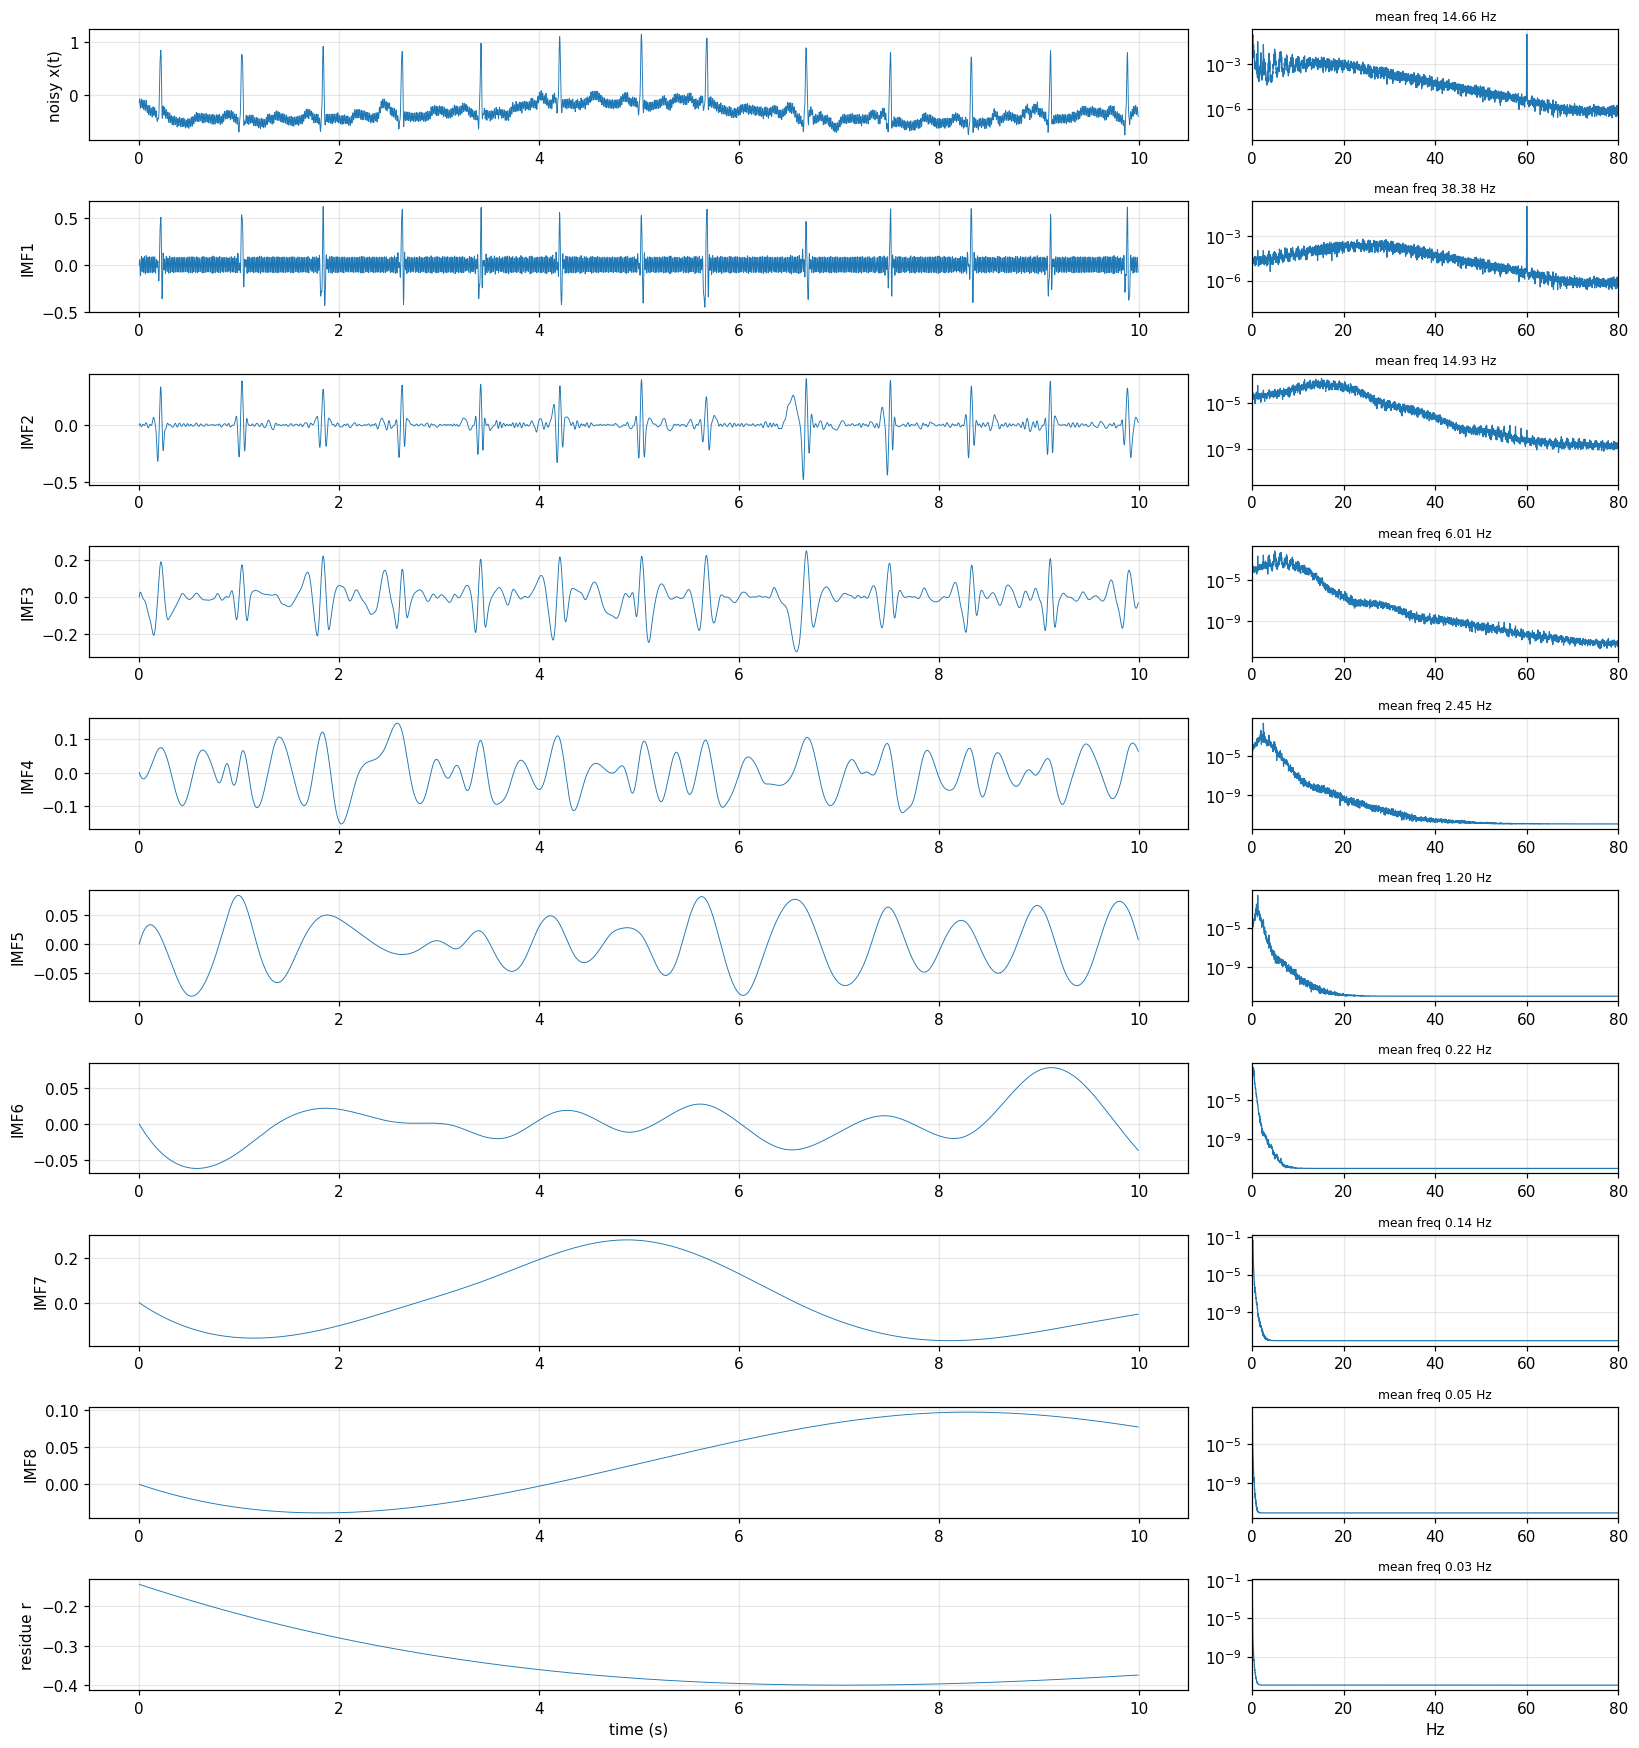

In [13]:
imfs, residue = emd_decompose(case["noisy"])
assert np.allclose(imfs.sum(0) + residue, case["noisy"])
t = np.arange(10 * fs) / fs
fig, axes = plt.subplots(10, 2, figsize=(15, 16), gridspec_kw={"width_ratios": [3, 1]})
rows = [("noisy x(t)", case["noisy"])] + [(f"IMF{k+1}", imfs[k]) for k in range(8)] + [("residue r", residue)]
for (name, s), (ax_t, ax_f) in zip(rows, axes):
    ax_t.plot(t, s[: len(t)], lw=0.6); ax_t.set_ylabel(name)
    f, P = welch(s - s.mean(), fs, nperseg=16384)
    ax_f.semilogy(f, P + 1e-12, lw=0.8); ax_f.set_xlim(0, 80)
    fc = np.sum(f * P) / np.sum(P)
    ax_f.set_title(f"mean freq {fc:.2f} Hz", fontsize=8)
axes[-1, 0].set_xlabel("time (s)"); axes[-1, 1].set_xlabel("Hz")
plt.tight_layout(); plt.show()

## Metrics (Eqs. 4–6)

In [14]:
xc = np.sin(np.linspace(0, 20, 1000)); xn = xc + 0.1; xd = xc + 0.01
assert np.isclose(snr_db(xc, xd), 10 * np.log10(np.sum(xc**2) / np.sum((xd - xc)**2)))
assert np.isclose(rmse(xc, xd), 0.01)
assert np.isclose(snr_improvement(xc, xn, xd), 10 * np.log10(np.sum((xn - xc)**2) / np.sum((xd - xc)**2)))
print("metrics match Eqs. (4)-(6)")

metrics match Eqs. (4)-(6)
